In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [3]:
# Change for your data
root_path = Path("/data/smfish/20260311_bartelle_smFISH_cryo_48hr_male")

In [4]:
output_dir = root_path / "big_fish" / "results" / "all_tiles_2D"
matrix_path = output_dir / "cellxgene_matrix.csv"
# spots_path_bit5 = os.path.join(output_dir, "spots_bit_5.csv")
matrix = pd.read_csv(matrix_path, usecols= ['cell_id', 'Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2',
       'Ptch1', 'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi', 'Aif1', 'Nnat'])
print(matrix.shape)
print(matrix.head())

(9709, 17)
   cell_id  Angpt1   Crmp1    Dcx  Hdac11  Itgam  Notch2  Ptch1  Serpine1  \
0        0    2748  119363  10559   78683  13164   10057  18360      8594   
1        1       0       1      0       0      0       0      0         0   
2        3       0       0      0       0      0       0      1         0   
3        5       0       1      0       0      0       0      3         0   
4        6       0      35      1      15      0       0      1         0   

    Shh  Slc1a3  Tcf12   Tek  Tgfb1  Tgfbi   Aif1   Nnat  
0  4103  103261   9700  8471  15820  13410  14236  13704  
1     0       1      0     0      0      0      0      0  
2     0       1      0     0      0      0      0      0  
3     0       9      0     0      0      0      0      3  
4     0       1      0     0      0      0      0      0  


# Filtering

In [5]:
# Select the columns representing gene counts
genes = matrix.columns.drop("cell_id")
# convert integer counts to floats
counts = matrix[genes].astype(float)

In [6]:
counts

,Angpt1,Crmp1,Dcx,Hdac11,Itgam,Notch2,Ptch1,Serpine1,Shh,Slc1a3,Tcf12,Tek,Tgfb1,Tgfbi,Aif1,Nnat
0,2748.0,119363.0,10559.0,78683.0,13164.0,10057.0,18360.0,8594.0,4103.0,103261.0,9700.0,8471.0,15820.0,13410.0,14236.0,13704.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,3.0
4,0.0,35.0,1.0,15.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9704,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
9705,0.0,32.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
9706,0.0,23.0,1.0,4.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
9707,0.0,4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
# Sum the total number of counts per cell
cell_total = counts.sum(axis=1)

In [24]:
cell_total.describe()

count      9709.000000
mean        113.743125
std        4508.222726
min           1.000000
25%          21.000000
50%          49.000000
75%          96.000000
max      444233.000000
dtype: float64

In [8]:
# Identify the cells whose total counts (across all genes) are in the top 1% (or above the 99th percentile)
cell_upper = cell_total.quantile(0.99)
high_total_cells = cell_total > cell_upper

# what is the 99th percentile of counts/cell
print(f"The 99th percentile threshold is {cell_upper}")

# How many cells will we drop?
print(f"The number of cells to be dropped is {high_total_cells.sum(axis=0)}")

The 99th percentile threshold is 290.9200000000001
The number of cells to be dropped is 98


In [10]:
# Drop those cells
filtered_counts = counts.loc[~high_total_cells]
filtered_counts.shape

(9611, 16)

In [26]:
filtered_counts.max()

Angpt1       21.0
Crmp1       174.0
Dcx          23.0
Hdac11      128.0
Itgam        54.0
Notch2       78.0
Ptch1        60.0
Serpine1    104.0
Shh          34.0
Slc1a3       94.0
Tcf12        49.0
Tek          99.0
Tgfb1        57.0
Tgfbi        82.0
Aif1         68.0
Nnat         86.0
dtype: float64

In [ ]:
# Another filtering step would be to remove any cell exceeding the 99th-percentile threshold for at least one gene.
# However, the 99th percentile for each gene is in the tens for many genes. It's quite low. I'm hesitant to throw away that data.
# Also would I do this filtering on counts or filtered_counts? That would change the effect.

# gene_upper = counts.quantile(0.99, axis=0)

# high_gene_cells = counts.gt(gene_upper, axis="columns").any(axis=1)

# filtered_counts = counts.loc[~high_gene_cells]



# Another way to do it: counts = counts[counts["Aif1"] <= float(gene_upper["Aif1"])-1]

# PCA

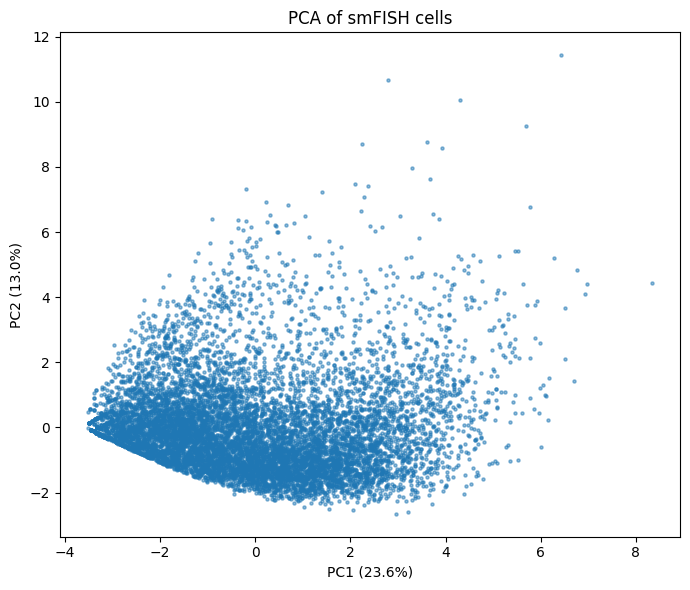

In [27]:
# Base-2 log transformation
# the data because counts span orders of magnitude. Brings data values closer together
# gene expression data is heavily right skewed
# add the +1 so that zero counts remain valid
log_counts = np.log2(filtered_counts + 1)

# Standardize genes and run PCA
scaled_counts = StandardScaler().fit_transform(log_counts)
pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled_counts)

# Plot cells in PCA space
plt.figure(figsize=(7, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=5, alpha=0.5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("PCA of smFISH cells")
plt.tight_layout()
plt.show()

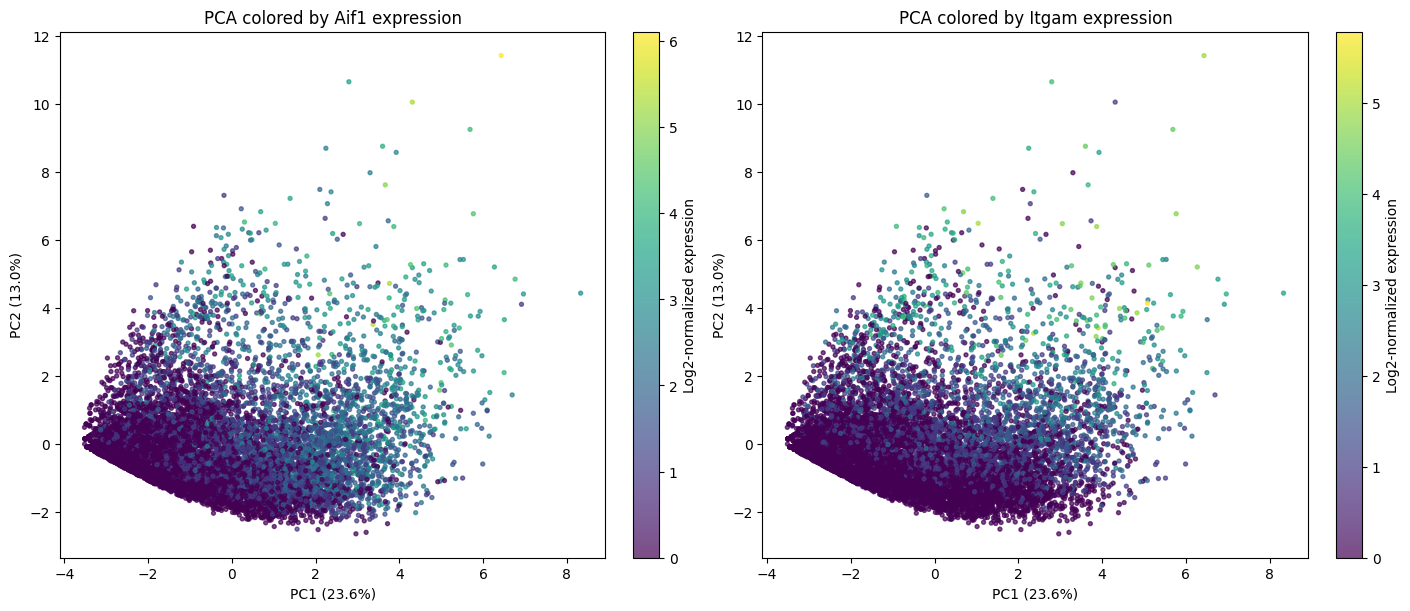

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

In [6]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# for ax, gene in zip(axes, ["Aif1", "Itgam"]):
#     expression = log_counts[gene].to_numpy()
#     positive = expression > 0

#     # Plot all cells gray first
#     ax.scatter(
#         pcs[:, 0],
#         pcs[:, 1],
#         color="lightgray",
#         s=8,
#         alpha=0.7,
#     )

#     # Overlay cells with detected expression
#     scatter = ax.scatter(
#         pcs[positive, 0],
#         pcs[positive, 1],
#         c=expression[positive],
#         cmap="viridis",
#         s=8,
#         alpha=0.7,
#     )

#     ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
#     ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
#     ax.set_title(f"PCA colored by {gene} expression")
#     fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

# plt.show()

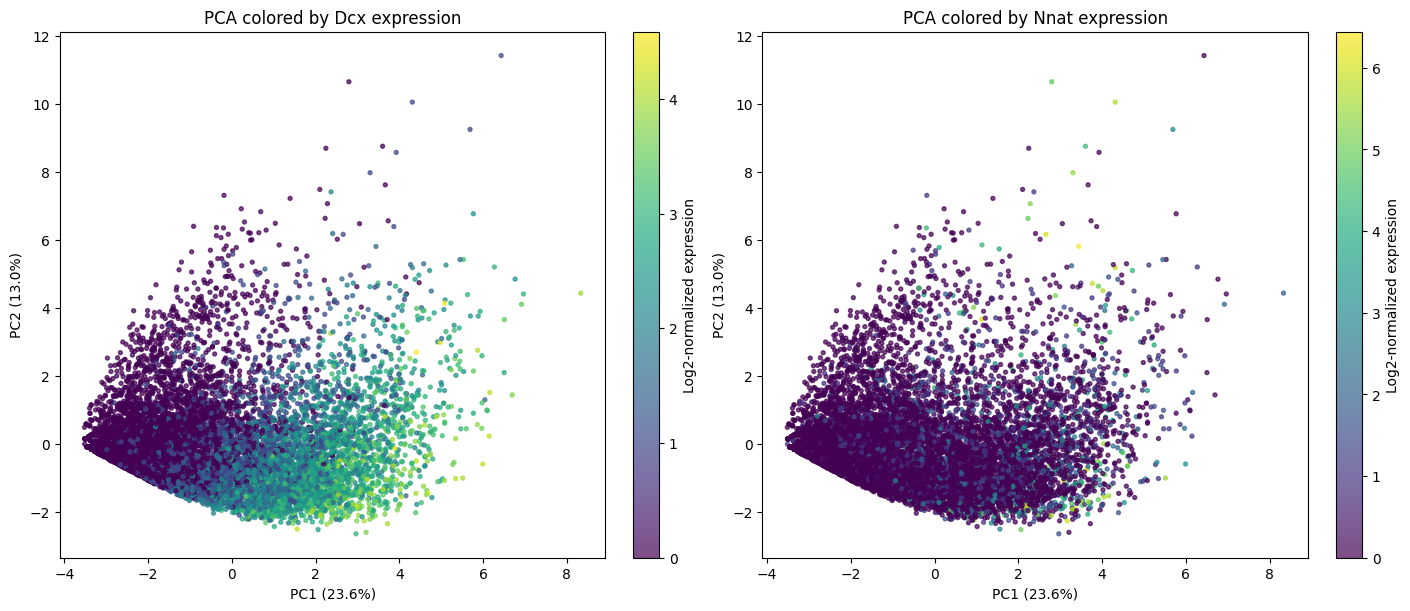

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Dcx", "Nnat"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

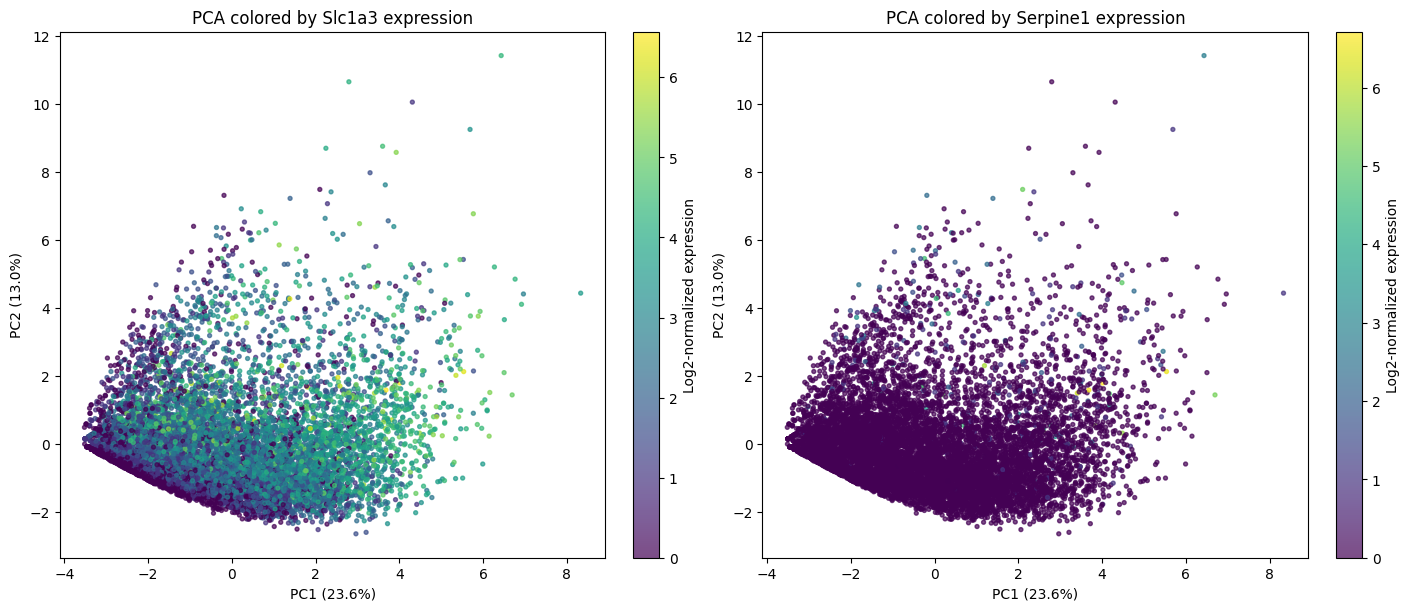

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Serpine1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

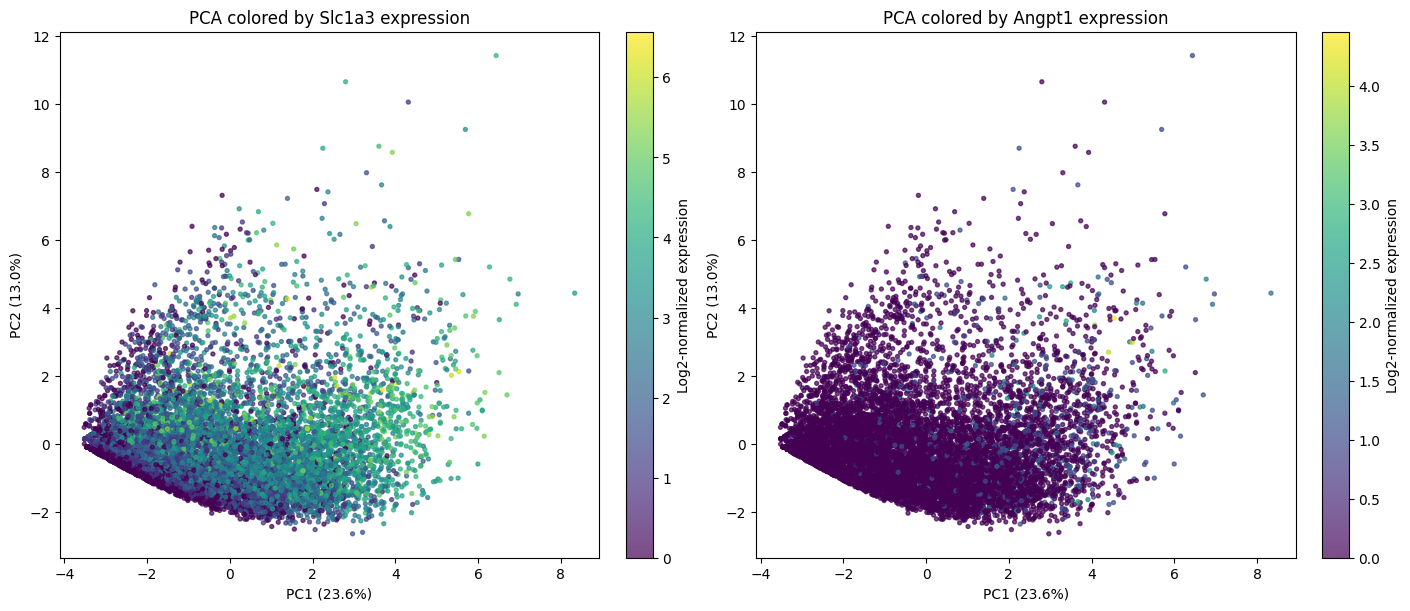

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Angpt1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

# Scatter plots

### This is the incorrect way of doing it because it contains library size normalization!!!
But it looks pretty, unfortunately.

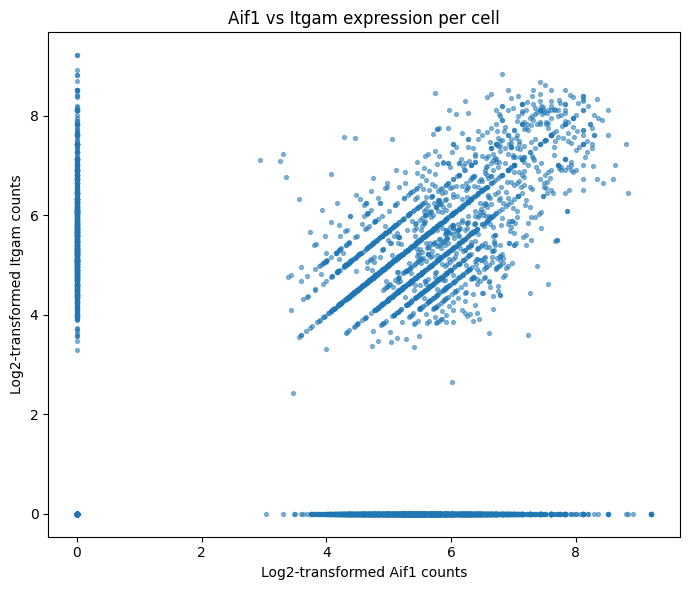

In [ ]:
### This is the incorrect way of doing it because it contains library size normalization!!!

# sum the total # of spots per cell
library_size = counts.sum(axis=1).replace(0, 1)

# library size normalization, then natural-log2 transformation log(1+x)
log_counts_lsn = (counts.div(library_size, axis=0) * 1e4).apply(np.log1p)


plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Aif1"],
    log_counts_lsn["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log2-transformed Aif1 counts")
plt.ylabel("Log2-transformed Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

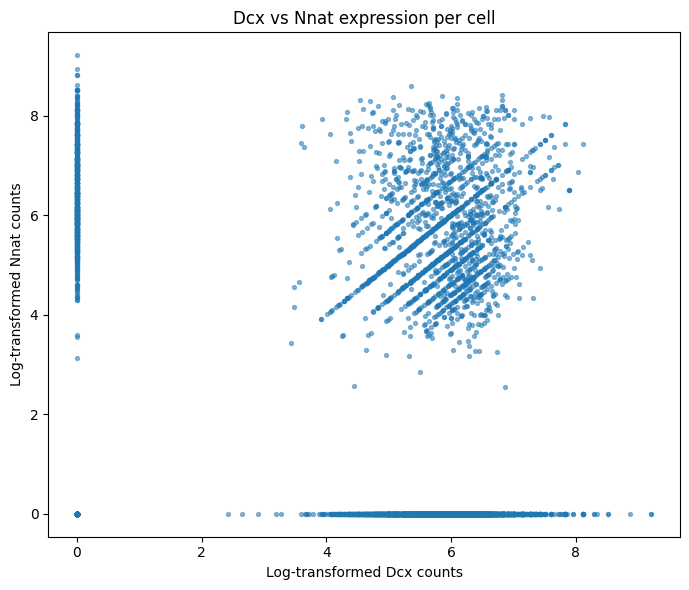

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Dcx"],
    log_counts_lsn["Nnat"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log-transformed Dcx counts")
plt.ylabel("Log-transformed Nnat counts")
plt.title("Dcx vs Nnat expression per cell")
plt.tight_layout()
plt.show()

### Real scatter plots

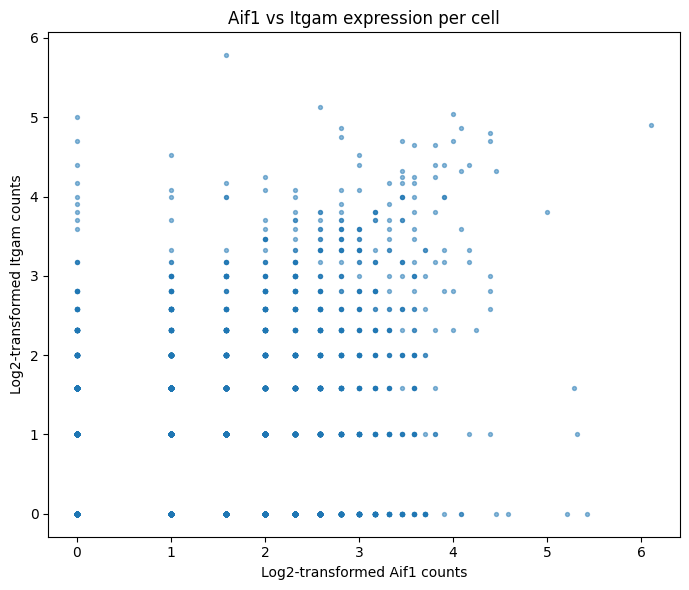

In [32]:
plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts["Aif1"],
    log_counts["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log2-transformed Aif1 counts")
plt.ylabel("Log2-transformed Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

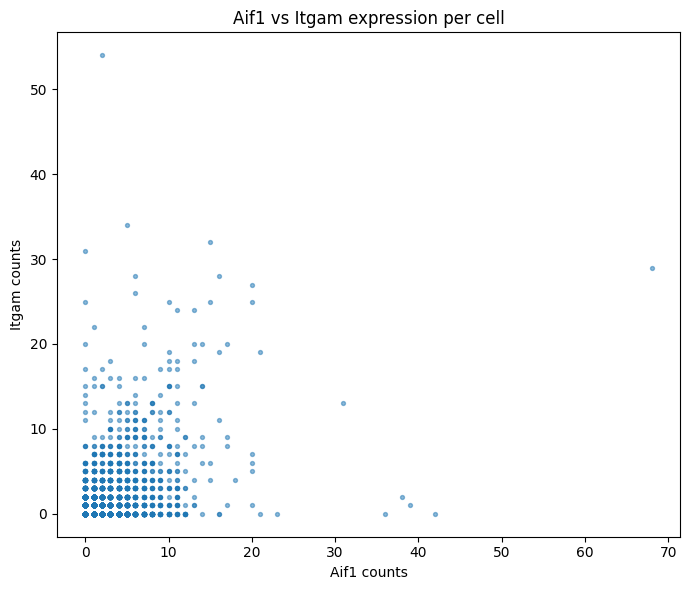

In [35]:
plt.figure(figsize=(7, 6))

plt.scatter(
    filtered_counts["Aif1"],
    filtered_counts["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Aif1 counts")
plt.ylabel("Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

# Elbow Plots

## Microglia

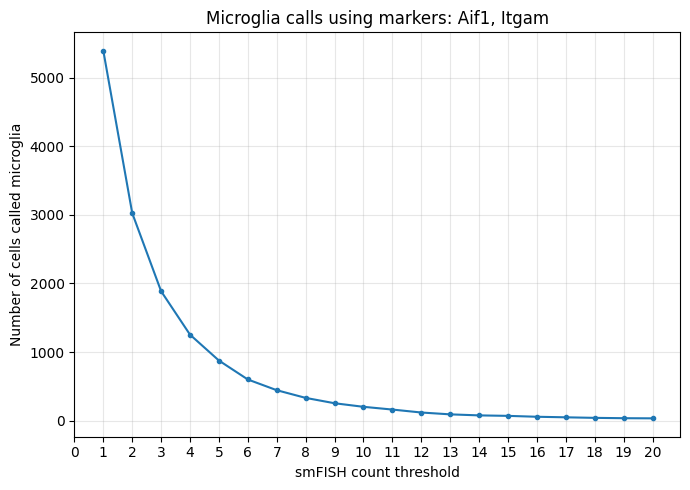

In [11]:
# Define marker genes for the cell type
marker_genes = ["Aif1", "Itgam"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

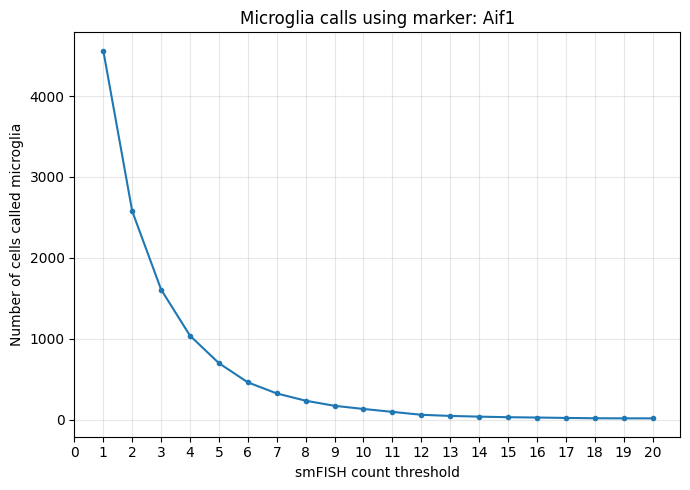

In [14]:
# Define marker genes for the cell type
marker_gene = ["Aif1"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

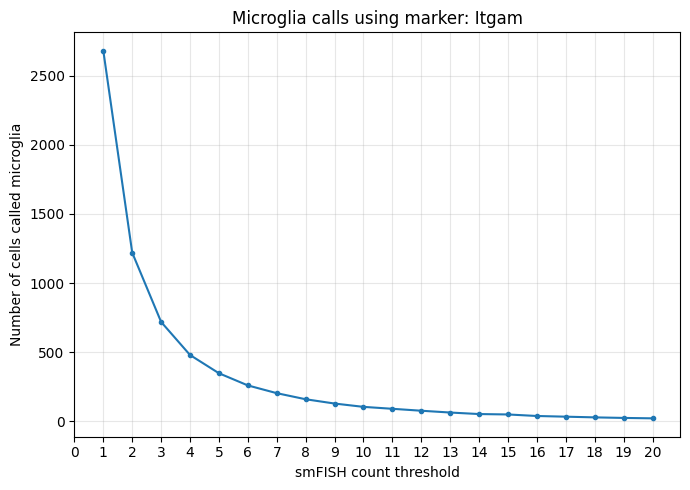

In [15]:
# Define marker genes for the cell type
marker_gene = ["Itgam"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Neural Progenitors

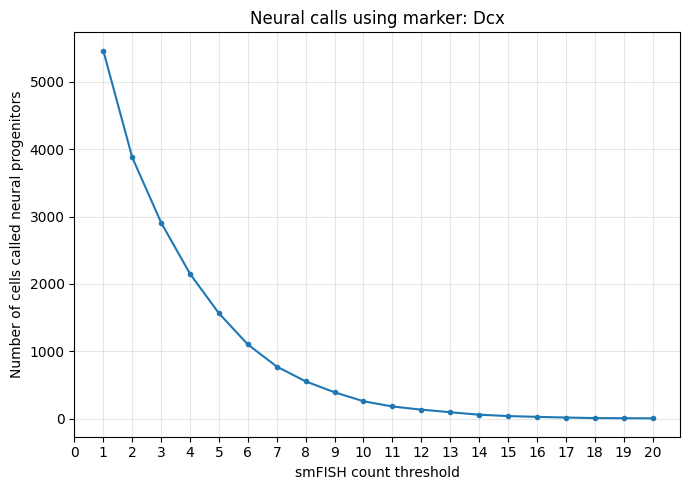

In [16]:
# Define marker genes for the cell type
marker_gene = ["Dcx"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

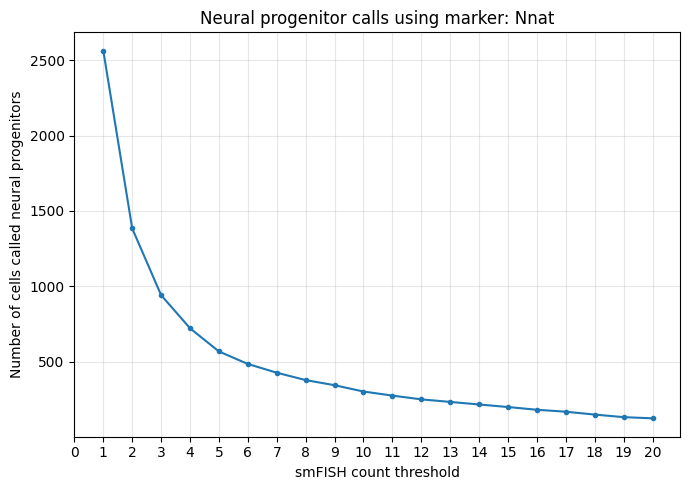

In [17]:
# Define marker genes for the cell type
marker_gene = ["Nnat"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

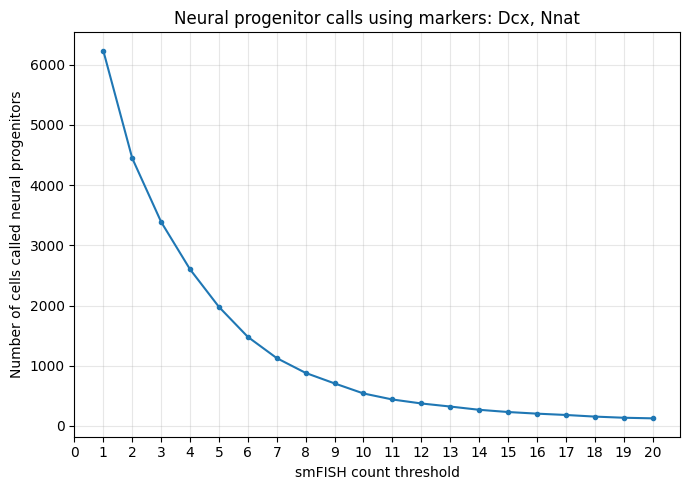

In [18]:
# Define marker genes for the cell type
marker_genes = ["Dcx", "Nnat"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Astrocytes

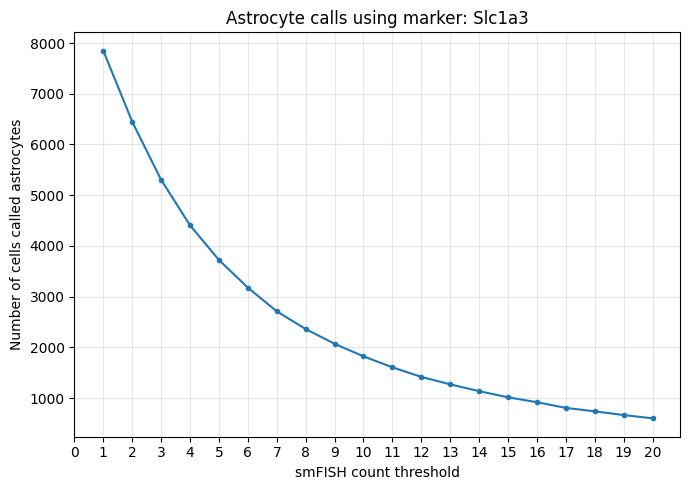

In [19]:
# Define marker genes for the cell type
marker_gene = ["Slc1a3"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
astrocyte_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, astrocyte_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called astrocytes")
plt.title(f"Astrocyte calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# UMAP